# 1 · Principal component analysis: statistical factors in equity sectors
PCA on the nine original SPDR sector ETFs (2005 to present). The first component is the market; the next ones show economically interpretable spreads. The rolling **absorption ratio** tracks how tightly markets move together, a known stress indicator.

In [1]:
import sys, pathlib, warnings
sys.path.insert(0, str(pathlib.Path.cwd().parent / "src"))
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
plt.rcParams.update({"figure.figsize": (10, 4.5), "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 110})
IMG = pathlib.Path("../images"); IMG.mkdir(exist_ok=True)
load = lambda f: pd.read_csv(f"../data/{f}.csv", index_col=0, parse_dates=True)   # refresh: python scripts/fetch_data.py
from finml import factors

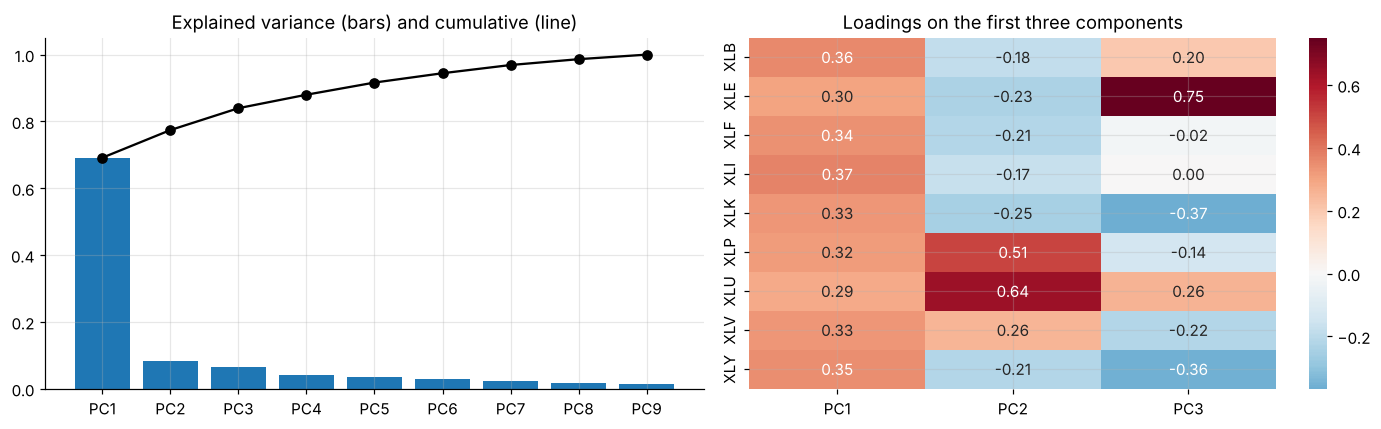

PC1    0.692
PC2    0.083
PC3    0.065
PC4    0.040
dtype: float64

In [2]:
px = load("sector_etfs"); spy = px.pop("SPY")
rets = np.log(px).diff().dropna()
model = factors.fit_pca(rets)
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].bar(model.explained.index, model.explained.values); ax[0].plot(model.explained.cumsum().values, "ko-")
ax[0].set_title("Explained variance (bars) and cumulative (line)")
sns.heatmap(model.loadings.iloc[:, :3], annot=True, fmt=".2f", cmap="RdBu_r", center=0, ax=ax[1])
ax[1].set_title("Loadings on the first three components")
fig.tight_layout(); plt.savefig(IMG / "pca_sectors.png", bbox_inches="tight"); plt.show()
model.explained.head(4).round(3)

**Interpretation**
* **PC1** loads positively on every sector: the market factor (it correlates very highly with SPY, below).
* **PC2** contrasts defensive sectors (utilities, staples, health care) with cyclicals (financials, energy, materials).
* **PC3** separates energy and materials from the rest: a commodity factor.

corr(PC1, SPY daily returns) = 0.971


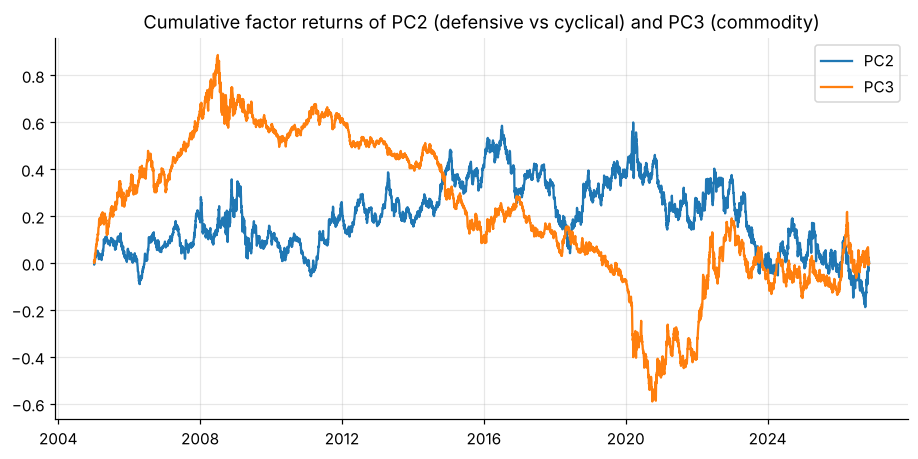

In [3]:
pc1_cum = model.factor_returns["PC1"]
print(f"corr(PC1, SPY daily returns) = {np.corrcoef(pc1_cum, np.log(spy).diff().loc[pc1_cum.index])[0, 1]:.3f}")
fig, ax = plt.subplots()
for k in ("PC2", "PC3"):
    ax.plot((model.factor_returns[k] * model.std.mean()).cumsum(), label=k)
ax.set_title("Cumulative factor returns of PC2 (defensive vs cyclical) and PC3 (commodity)"); ax.legend(); plt.show()

## Absorption ratio: market coupling over time

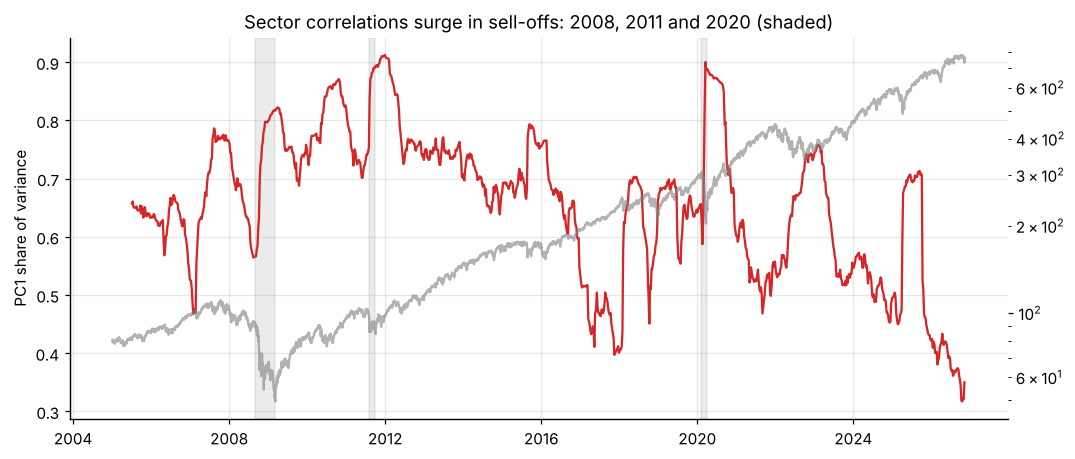

In [4]:
ar = factors.absorption_ratio(rets, window=126, k=1)
fig, ax1 = plt.subplots(figsize=(11, 4.5))
ax1.plot(ar, color="tab:red", label="absorption ratio (PC1 share, 6m window)"); ax1.set_ylabel("PC1 share of variance")
ax2 = ax1.twinx(); ax2.plot(spy, color="grey", alpha=0.6, label="SPY"); ax2.set_yscale("log"); ax2.grid(False)
for s, e in [("2008-09", "2009-03"), ("2011-08", "2011-10"), ("2020-02", "2020-04")]:
    ax1.axvspan(pd.Timestamp(s), pd.Timestamp(e), color="k", alpha=0.08)
ax1.set_title("Sector correlations surge in sell-offs: 2008, 2011 and 2020 (shaded)")
plt.savefig(IMG / "absorption_ratio.png", bbox_inches="tight"); plt.show()

In [5]:
# reconstruction: how much of each sector's variance do k factors explain?
r2 = pd.DataFrame({k: 1 - ((rets - model.reconstruct(k)) ** 2).sum() / ((rets - rets.mean()) ** 2).sum() for k in (1, 2, 3)})
r2.columns = [f"{k} factor(s)" for k in r2.columns]
r2.round(3)

,1 factor(s),2 factor(s),3 factor(s)
XLB,0.798,0.823,0.847
XLE,0.557,0.597,0.929
XLF,0.721,0.755,0.755
XLI,0.863,0.884,0.884
XLK,0.697,0.741,0.821
XLP,0.635,0.826,0.837
XLU,0.509,0.814,0.854
XLV,0.675,0.724,0.753
XLY,0.770,0.804,0.878
